# GLoW amplification factors for five lens models

This notebook evaluates the complex wave-optics amplification factor $F$ with the installed
[GLoW package](https://github.com/glow-astro/GLoW) for an isolated point mass (PM), a PM with
external shear, an isolated singular isothermal sphere (SIS), an SIS with external shear, and a
spherical Navarro–Frenk–White (NFW) lens. Independent formula evaluations check the isolated PM
and SIS cases. Published figures provide additional visual checks.

The dimensionless frequency is $w=2\pi f t_0$. For a PM of redshifted mass $M_{Lz}$,
$t_0=4GM_{Lz}/c^3$, so $w=8\pi GM_{Lz}f/c^3$. An SIS or NFW needs its own chosen physical
length and time scale before $w$ can be converted to Hz. For orientation, a $100M_\odot$ PM has
$f\simeq80.8(w/1)$ Hz. All plots use $w$ to keep the lens calculations comparable.

The diffraction integral uses $\phi(\mathbf x,\mathbf y)=|\mathbf x-\mathbf y|^2/2-\psi(\mathbf x)$:

$$F(w,\mathbf y)=\frac{w}{2\pi i}\int d^2x\,e^{iw[\phi(\mathbf x,\mathbf y)-\phi_{\min}(\mathbf y)]}.$$

Subtracting the earliest image delay $\phi_{\min}$ fixes an arbitrary phase reference and leaves
$|F|$ unchanged. This is GLoW's convention. The plots show $|F|$ and $\arg F$ separately;
$|F|^2$ is the flux magnification.

Sources: [Takahashi & Nakamura (2003), Eqs. 17–20 and Figs. 2–3](https://arxiv.org/pdf/astro-ph/0305055);
[Villarrubia-Rojo et al. (2025), Eqs. 55, 65 and Figs. 8–9](https://arxiv.org/pdf/2409.04606);
[Ephremidze, Kamionkowski & Dvorkin (2026), FIONA, Fig. 10 and Appendix B](https://arxiv.org/pdf/2603.12333).


In [1]:
import os
# Set library thread limits before importing NumPy or GLoW.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/test_glow_matplotlib")

import shutil
from importlib.metadata import version
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt
from matplotlib import rcParams
from cycler import cycler
from numpy.polynomial.legendre import leggauss
from scipy.special import fresnel
from glow import lenses, time_domain_c, freq_domain_c, freq_domain

my_colors = ['navy', 'coral', 'c', 'crimson', 'springgreen', 'gold',
             'dodgerblue', 'hotpink', 'forestgreen', 'moccasin', 'darkred', 'teal']
tex_ready = (shutil.which('latex') and shutil.which('dvipng') and
             shutil.which('kpsewhich') and os.popen('kpsewhich txfonts.sty').read().strip())
rc_params = {'axes.labelsize': 14, 'axes.titlesize': 14, 'legend.fontsize': 12,
             'xtick.labelsize': 12, 'ytick.labelsize': 12,
             'text.usetex': bool(tex_ready), 'text.latex.preamble': r'\usepackage{txfonts}',
             'font.size': 14, 'font.family': 'serif', 'font.serif': 'times',
             'mathtext.default': 'sf', 'lines.markeredgewidth': 1,
             'lines.linewidth': 2, 'axes.prop_cycle': cycler(color=my_colors)}
rcParams.update(rc_params)
if not tex_ready:
    rcParams['font.serif'] = ['DejaVu Serif']
    print('Install dvipng separately (for example, sudo apt install dvipng) to enable LaTeX figure labels. Using Matplotlib math text meanwhile.')
print(f"GLoW {version('glow')}; NumPy {version('numpy')}; SciPy {version('scipy')}")

Install dvipng separately (for example, sudo apt install dvipng) to enable LaTeX figure labels. Using Matplotlib math text meanwhile.
GLoW 0.1; NumPy 1.26.4; SciPy 1.15.2


## Formula checks

For an isolated PM, write $u=w/2$, $x_m=(y+\sqrt{y^2+4})/2$, and
$\phi_m=(x_m-y)^2/2-\ln x_m$. Takahashi and Nakamura's Eq. 17 gives

$$F_{\rm PM}=e^{\pi w/4+iw[\ln(w/2)-2\phi_m]/2}
\Gamma(1-iw/2)\,{}_1F_1(iw/2;1;iwy^2/2).$$

The independent evaluation below uses `mpmath` at 40 decimal digits.

For an isolated SIS, $\psi=\psi_0 r$. Takahashi and Nakamura's Eq. 19 is a radial
Bessel integral; Eq. 65 of the GLoW paper reduces it to a one-dimensional angular integral.
Define $a(\theta)=\psi_0+y\cos\theta$ and
$\alpha=\sqrt{w/\pi}\,a$. With Fresnel functions
$C(z)+iS(z)=\int_0^z e^{i\pi t^2/2}dt$, an equivalent expression is

$$F_{\rm SIS}=e^{iw[y^2/2-\phi_m]}
\left[1-i\int_0^\pi d\theta\,\alpha e^{-i\pi\alpha^2/2}
\left(\frac{1+i}{2}+C(\alpha)+iS(\alpha)\right)\right],
\quad\phi_m=-\psi_0y-\psi_0^2/2.$$

This follows by doing the radial Gaussian integral first. The code evaluates the remaining
angular integral with 256-point Gauss–Legendre quadrature (768 points for the high-frequency $y=3$ curve); it does not call GLoW's SIS routine.


In [2]:
def point_mass_formula(w, y):
    """Independent evaluation of Takahashi & Nakamura (2003), Eq. 17."""
    mp.mp.dps = 40
    x_min = (y + np.sqrt(y*y + 4)) / 2
    phi_min = (x_min - y)**2 / 2 - np.log(x_min)
    result = []
    for frequency in np.atleast_1d(w):
        u = mp.mpf(float(frequency)) / 2
        prefactor = mp.exp(mp.pi*u/2 + 1j*u*(mp.log(u) - 2*phi_min))
        result.append(complex(prefactor * mp.gamma(1 - 1j*u)
                              * mp.hyp1f1(1j*u, 1, 1j*u*y*y)))
    return np.array(result)


def sis_formula(w, y, psi0=1.0, n_angle=256):
    """Independent Fresnel-integral form of GLoW (2025), Eq. 65."""
    nodes, weights = leggauss(n_angle)
    theta = np.pi*(nodes + 1)/2
    answer = []
    phi_min = -psi0*y - psi0**2/2
    for frequency in np.atleast_1d(w):
        alpha = np.sqrt(frequency/np.pi)*(psi0 + y*np.cos(theta))
        s, c = fresnel(alpha)
        integrand = alpha*np.exp(-0.5j*np.pi*alpha**2)*((1 + 1j)/2 + c + 1j*s)
        answer.append(np.exp(1j*frequency*(y*y/2 - phi_min))
                      * (1 - 1j*np.pi/2*np.dot(weights, integrand)))
    return np.array(answer)


def geometric_optics(w, images):
    """Stationary-phase image sum; Takahashi & Nakamura (2003), Eq. 15."""
    time_min = images[0]['t']
    result = np.zeros_like(w, dtype=complex)
    morse = {'min': 0, 'saddle': 0.5, 'max': 1}
    for image in images:
        if image['type'] not in morse:  # singular cusp is not an ordinary image
            continue
        result += np.sqrt(abs(image['mag'])) * np.exp(
            1j*w*(image['t'] - time_min) - 1j*np.pi*morse[image['type']]
        )
    return result

# The two independently evaluated formulas should reproduce GLoW's dedicated routines.
probe_w = np.array([0.1, 1, 10, 30])
for label, reference, fast in [
    ('PM', point_mass_formula(probe_w, 0.3),
     freq_domain_c.Fw_AnalyticPointLens_C(0.3, {'parallel': False})(probe_w)),
    ('SIS', sis_formula(probe_w, 0.3),
     freq_domain_c.Fw_SemiAnalyticSIS_C(0.3, {'parallel': False})(probe_w))]:
    error = np.max(np.abs((fast - reference)/reference))
    print(f'{label}: maximum dedicated-routine/formula difference = {error:.2e}')
    assert error < 1e-5

PM: maximum dedicated-routine/formula difference = 9.17e-07
SIS: maximum dedicated-routine/formula difference = 1.18e-09


## Five lens configurations

The representative source lies on the $x_1$ axis at $\mathbf y=(0.3,0)$.
The point mass and SIS have $\psi_0=1$. The external field has
$\gamma_1=0.05$, $\gamma_2=0$, and $\kappa=0$, so
$\psi_{\rm sh}=\gamma_1(x_1^2-x_2^2)/2$.
The NFW case has $\psi_0=2$ and $x_s=1$ in GLoW's dimensionless units.
These choices make diffraction, interference, and the effect of a modest shear visible.

All five curves use GLoW's numerical time-domain method followed by its regularized FFT.
The isolated lenses use a radial integral; the shear cases use two-dimensional contours.
The dashed curves give an independent formula for the isolated PM and SIS, the corresponding
isolated lens for the shear cases, and geometric optics for NFW. Dotted curves show the
geometric-optics limit of each configuration, which is expected to work only at high $w$.


In [3]:
SOURCE_Y = 0.3
SHEAR = 0.05
W = np.r_[np.geomspace(0.01, 1, 180), np.linspace(1.01, 100, 1200)]

models = {
    'Isolated PM': lenses.Psi_PointLens({'psi0': 1}),
    'PM + external shear': lenses.CombinedLens({'lenses': [
        lenses.Psi_PointLens({'psi0': 1}), lenses.Psi_Ext({'gamma1': SHEAR})]}),
    'Isolated SIS': lenses.Psi_SIS({'psi0': 1}),
    'SIS + external shear': lenses.CombinedLens({'lenses': [
        lenses.Psi_SIS({'psi0': 1}), lenses.Psi_Ext({'gamma1': SHEAR})]}),
    'NFW': lenses.Psi_NFW({'psi0': 2, 'xs': 1}),
}


def glow_numerical(lens, y, w_min=0.01, w_max=100, nt=5000, n_above_discard=7):
    """Compute GLoW's regularized time-domain FFT with one CPU thread."""
    method = (time_domain_c.It_SingleIntegral_C if lens.isAxisym
              else time_domain_c.It_MultiContour_C)
    response = method(lens, y, {'Nt': nt, 'tmax': 1e5, 'parallel': False})
    amplification = freq_domain_c.Fw_FFT_C(
        response, {'wmin': w_min, 'wmax': w_max, 'parallel': False,
                   'eval_mode': 'exact', 'N_above_discard': n_above_discard}
    )
    return response, amplification

results = {}
for name, lens in models.items():
    response, amplification = glow_numerical(lens, SOURCE_Y)
    results[name] = {'response': response, 'F': amplification(W)}
    print(f'{name}: {len(response.p_crits)} critical points; '
          f'{sum(p["type"] in ("min", "saddle", "max") for p in response.p_crits)} ordinary images')

Isolated PM: 3 critical points; 2 ordinary images


PM + external shear: 3 critical points; 2 ordinary images
Isolated SIS: 3 critical points; 2 ordinary images
SIS + external shear: 3 critical points; 2 ordinary images
NFW: 1 critical points; 1 ordinary images


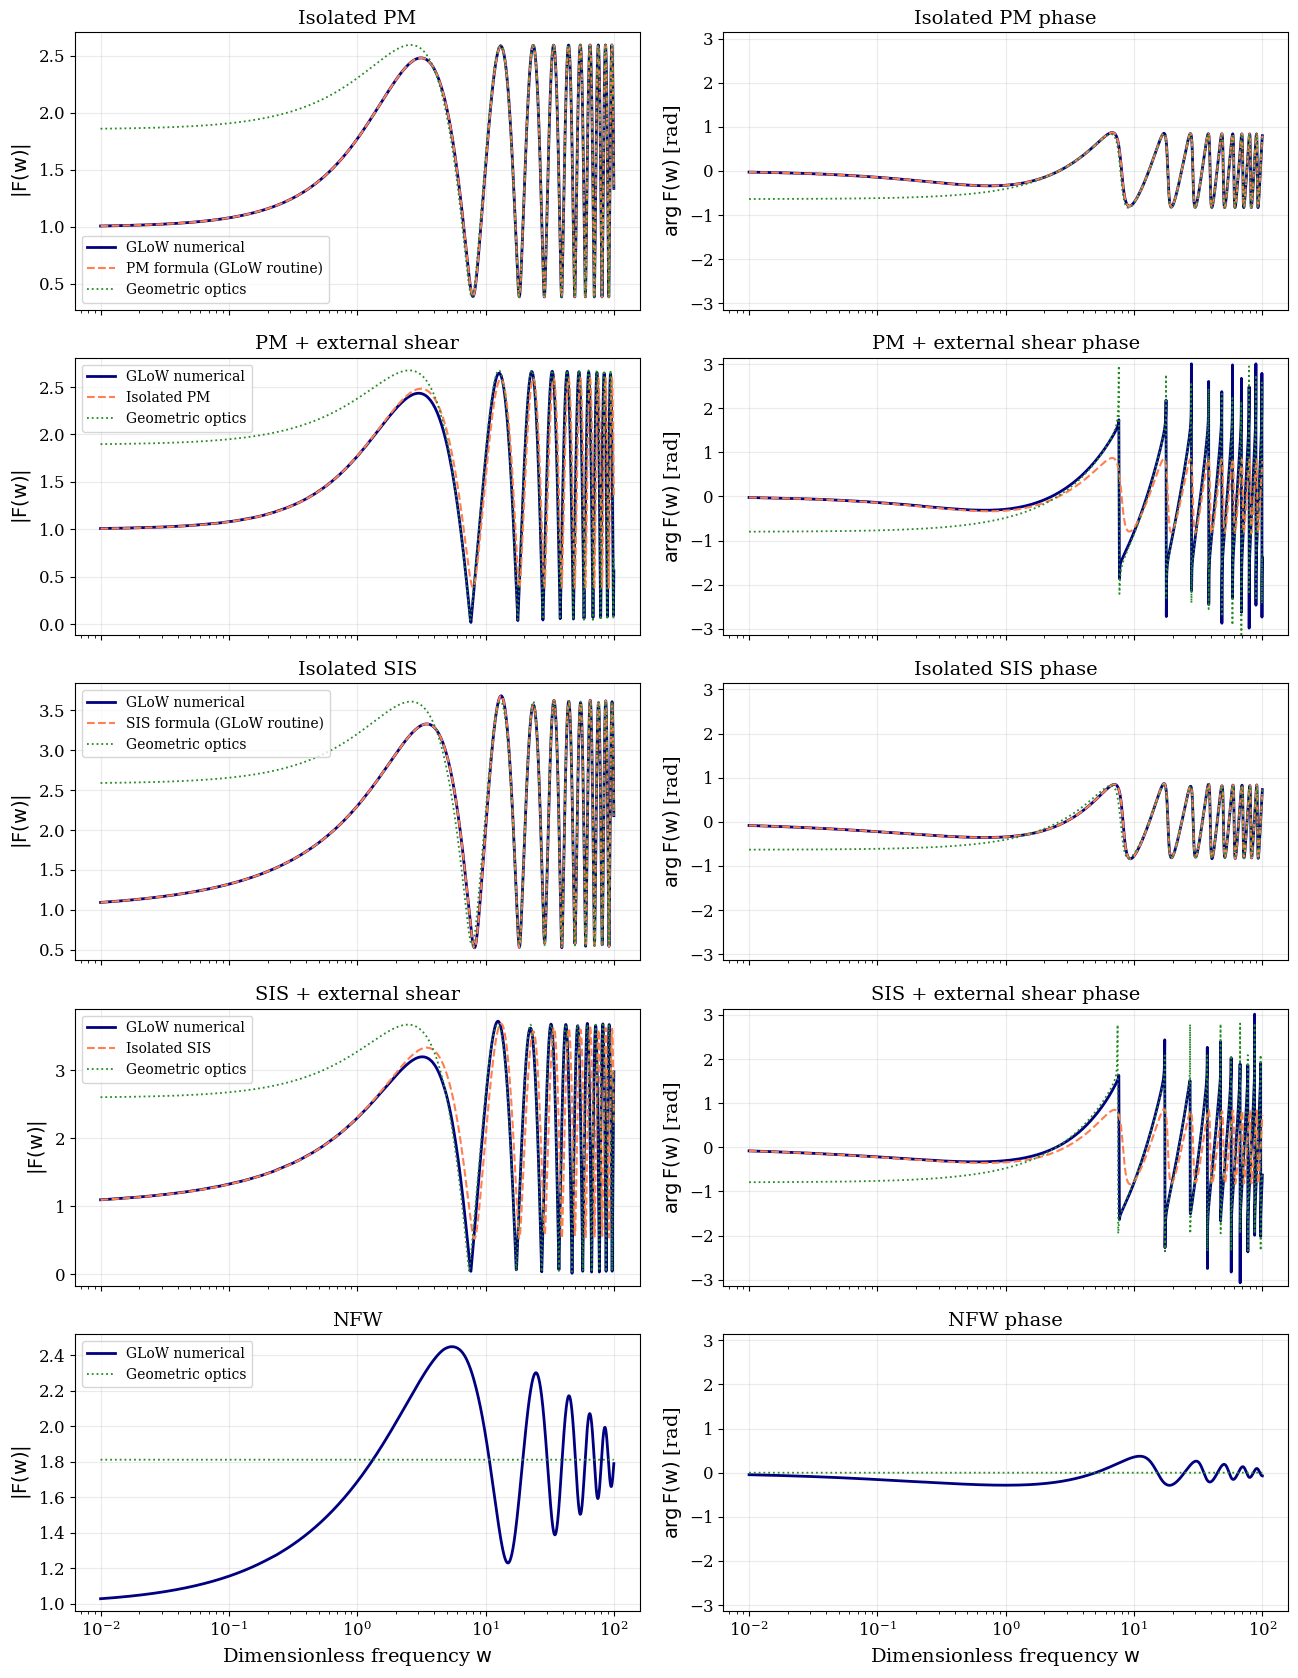

In [4]:
# Show amplitude and phase for every requested lens model.
fig, axes = plt.subplots(5, 2, figsize=(13.2, 17), sharex=True)
for row, (name, entry) in enumerate(results.items()):
    f_glow = entry['F']
    if name == 'Isolated PM':
        comparison = freq_domain_c.Fw_AnalyticPointLens_C(
            SOURCE_Y, {'parallel': False})(W)
        comparison_label = 'PM formula (GLoW routine)'
    elif name == 'Isolated SIS':
        comparison = freq_domain_c.Fw_SemiAnalyticSIS_C(
            SOURCE_Y, {'parallel': False})(W)
        comparison_label = 'SIS formula (GLoW routine)'
    elif name == 'PM + external shear':
        comparison = results['Isolated PM']['F']
        comparison_label = 'Isolated PM'
    elif name == 'SIS + external shear':
        comparison = results['Isolated SIS']['F']
        comparison_label = 'Isolated SIS'
    else:
        comparison = None
        comparison_label = None

    f_geo = geometric_optics(W, entry['response'].p_crits)
    amp_ax, phase_ax = axes[row]
    amp_ax.plot(W, abs(f_glow), color='navy', label='GLoW numerical')
    if comparison is not None:
        amp_ax.plot(W, abs(comparison), color='coral', ls='--', lw=1.5,
                    label=comparison_label)
    amp_ax.plot(W, abs(f_geo), color='forestgreen', ls=':', lw=1.3,
                label='Geometric optics')
    amp_ax.set(ylabel=r'$|F(w)|$', title=name, xscale='log')
    amp_ax.grid(alpha=0.25)
    amp_ax.legend(fontsize=10, loc='best')

    phase_ax.plot(W, np.angle(f_glow), color='navy', label='GLoW numerical')
    if comparison is not None:
        phase_ax.plot(W, np.angle(comparison), color='coral', ls='--', lw=1.5,
                      label=comparison_label)
    phase_ax.plot(W, np.angle(f_geo), color='forestgreen', ls=':', lw=1.3,
                  label='Geometric optics')
    phase_ax.set(ylabel=r'$\arg F(w)$ [rad]', title=name + ' phase', xscale='log',
                 ylim=(-np.pi, np.pi))
    phase_ax.grid(alpha=0.25)

for ax in axes[-1]:
    ax.set_xlabel(r'Dimensionless frequency $w$')
fig.tight_layout()
plt.show()

The numerical and formula curves overlap for the isolated lenses at this scale.
The shear changes the arrival times and magnifications, so the interference peaks move.
For NFW, the high-frequency geometric curve follows the ordinary image contribution;
at lower $w$, diffraction and the NFW cusp are important. Phase wraps at $\pm\pi$
are display choices, not physical discontinuities.


## Point mass with external shear: source derivative series

[Venumadhav, *Relative binning for gravitational-wave microlensing in the Chang–Refsdal model*,
Sec. II B and Appendix C](relative_binning_chang_refsdal_v5.pdf) evaluates the full wave-optics
amplification from the isolated point mass solution. For the case here, the source is
$\mathbf y=(y,0)$, the shear is aligned with the $x_1$ axis, and $\kappa=0$. After removing the
source phase, the paper's exact identity is

$$G_\gamma(w,y)=\exp\!\left[\frac{i\gamma}{2w}
(\partial_{y_1}^2-\partial_{y_2}^2)\right]G_{\rm PM}(w,y),\qquad
G_{\rm PM}(w,s)=C(w)\,{}_1F_1(1-iw/2;1;-iws/2),\quad s=|\mathbf y|^2,$$

$$C(w)=e^{\pi w/4+(iw/2)\ln(w/2)}\Gamma(1-iw/2),\qquad
F_\gamma=e^{iw(y^2/2-\phi_{\min})}G_\gamma.$$

We expand the operator exponential in shear. Its radial derivative of order $r$ is [Eq. C3](relative_binning_chang_refsdal_v5.pdf):

$$\frac{d^rG_{\rm PM}}{ds^r}=C(w)\frac{(-iw/2)^r(1-iw/2)_r}{r!}
{}_1F_1(1-iw/2+r;1+r;-iws/2).$$

For aligned shear, $D=\partial_{y_1}^2-\partial_{y_2}^2$. The coefficients below apply
$D^n$ to a radial function without finite differences:

$$D^nG(s)\big|_{(y,0)}=
\sum_{j=0}^n(-1)^j{n\choose j}\frac{(2j)!}{j!}
\sum_{k=n-j}^{2(n-j)}
\frac{[2(n-j)]!(2y)^{2k-2(n-j)}}{[2(n-j)-k]![2k-2(n-j)]!}
G^{(j+k)}(s).$$

The series stops when four successive terms are below $2\times10^{-12}$ of the running sum,
as in the PDF. `mpmath` uses 50 decimal digits to protect cancellation. The positive image
position $x_+=[y+\sqrt{y^2+4(1-\gamma)}]/[2(1-\gamma)]$ gives the minimum delay
$\phi_{\min}=(1-\gamma)x_+^2/2-yx_++y^2/2-\ln x_+$. This fixes the same phase
reference as GLoW. The implementation covers the aligned, zero-convergence configuration
used here; the paper also describes arbitrary shear orientation and convergence.

In [5]:
from math import comb, factorial


def radial_operator_weights(order, y):
    """Coefficients of D^order G(y_1^2+y_2^2) at (y, 0), for D=d_11-d_22.

    This is the aligned-source form of Venumadhav's source-plane operator,
    Appendix C of relative_binning_chang_refsdal_v5.pdf. The key is the order
    of the radial derivative G^(r), and the value is its polynomial weight.
    """
    weights = {}
    for j in range(order + 1):
        m = order - j
        for k in range(m, 2*m + 1):
            r = j + k
            integer_factor = (-1)**j * comb(order, j) * factorial(2*j)//factorial(j)
            integer_factor *= factorial(2*m)//(factorial(2*m-k)*factorial(2*k-2*m))
            weights[r] = weights.get(r, 0) + integer_factor*(2*y)**(2*k-2*m)
    return [(r, value) for r, value in weights.items() if value != 0]


class ChangRefsdalOperator:
    """Analytic point-mass source-derivative series for aligned external shear.

    Evaluates Eqs. (9), (11), (12), and (C3) of
    relative_binning_chang_refsdal_v5.pdf. The source is (y, 0), beta=0,
    kappa=0, and the point-mass potential is ln|x|.
    """
    def __init__(self, y, gamma, max_order=40, tolerance=2e-12, digits=50):
        self.digits = digits
        self.tolerance = tolerance
        with mp.workdps(digits):
            self.y = mp.mpf(str(y))
            self.gamma = mp.mpf(str(gamma))
            self.weights = [radial_operator_weights(n, self.y)
                            for n in range(max_order + 1)]
            x_plus = (self.y + mp.sqrt(self.y**2 + 4*(1-self.gamma)))/(2*(1-self.gamma))
            self.phi_min = ((1-self.gamma)*x_plus**2/2 - self.y*x_plus
                            + self.y**2/2 - mp.log(x_plus))
        self.last_orders = None
        self.last_relative_terms = None

    def one_frequency(self, frequency):
        """Return F, the last shear order, and its relative term size."""
        with mp.workdps(self.digits):
            w = mp.mpf(float(frequency))
            a = 1 - 1j*w/2
            z = -1j*w*self.y**2/2
            prefactor = mp.exp(mp.pi*w/4 + 1j*w*mp.log(w/2)/2)*mp.gamma(a)
            radial_derivatives = []
            total = mp.mpc(0)
            small_terms = 0
            relative_term = mp.inf

            for n, weights in enumerate(self.weights):
                term = mp.mpc(0)
                for r, weight in weights:
                    while len(radial_derivatives) <= r:
                        k = len(radial_derivatives)
                        radial_derivatives.append(
                            (-1j*w/2)**k * mp.rf(a, k)/mp.factorial(k)
                            * mp.hyp1f1(a+k, 1+k, z)
                        )
                    term += weight*radial_derivatives[r]
                term *= (1j*self.gamma/(2*w))**n/mp.factorial(n)
                total += term
                relative_term = abs(term)/abs(total)
                small_terms = small_terms + 1 if n and relative_term < self.tolerance else 0
                if small_terms == 4:
                    break
            if small_terms < 4:
                raise RuntimeError('Shear series did not converge; increase max_order or digits')

            phase = mp.exp(1j*w*(self.y**2/2 - self.phi_min))
            return complex(phase*prefactor*total), n, float(relative_term)

    def __call__(self, frequencies):
        """Evaluate F at a frequency array and retain convergence diagnostics."""
        evaluated = [self.one_frequency(w) for w in np.atleast_1d(frequencies)]
        self.last_orders = np.array([item[1] for item in evaluated])
        self.last_relative_terms = np.array([item[2] for item in evaluated])
        return np.array([item[0] for item in evaluated])


operator_pm_shear = ChangRefsdalOperator(SOURCE_Y, SHEAR)
probe = np.array([0.1, 1.0, 10.0, 30.0])
operator_zero_shear = ChangRefsdalOperator(SOURCE_Y, 0.0)(probe)
zero_shear_error = np.max(abs(operator_zero_shear/point_mass_formula(probe, SOURCE_Y) - 1))
print(f'Zero-shear limit versus independent PM formula: {zero_shear_error:.2e}')
assert zero_shear_error < 1e-12

Zero-shear limit versus independent PM formula: 1.96e-15


In [6]:
# Independent check of the shear series against the diffraction integral.
# Rotating the radial contour by pi/4 makes its quadratic phase decay.
# The angular integral is a rapidly convergent Bessel series for this shear.
def chang_refsdal_contour_integral(w, y, gamma, angular_order=12):
    """Numerical contour evaluation of the paper's lens-plane integral, Eq. (5)."""
    with mp.workdps(35):
        w, y, gamma = (mp.mpf(str(value)) for value in (w, y, gamma))

        def integrand(u):
            radius = mp.exp(1j*mp.pi/4)*mp.sqrt(2*u/w)
            argument = w*y*radius
            angular = mp.besselj(0, argument)*mp.besseli(0, gamma*u)
            for m in range(1, angular_order):
                angular += 2*(-1)**m*mp.besseli(m, gamma*u)*mp.besselj(2*m, argument)
            return mp.exp(-u - 1j*w*mp.log(radius))*angular

        unshifted = mp.exp(1j*w*y*y/2)*mp.quad(integrand, [0, 1, 5, 20, 80])
        return complex(unshifted*mp.exp(-1j*w*operator_pm_shear.phi_min))

for frequency in (1.0, 5.0, 10.0):
    from_series = operator_pm_shear(np.array([frequency]))[0]
    from_integral = chang_refsdal_contour_integral(frequency, SOURCE_Y, SHEAR)
    difference = abs(from_series/from_integral - 1)
    print(f'w={frequency:g}: source-derivative series / independent contour integral - 1 = '
          f'{difference:.2e}')
    assert difference < 1e-9

w=1: source-derivative series / independent contour integral - 1 = 0.00e+00


w=5: source-derivative series / independent contour integral - 1 = 1.11e-16


w=10: source-derivative series / independent contour integral - 1 = 0.00e+00


GSL ERROR: endpoints do not straddle y=0 [brent.c:74]


GLoW, 5,000 points: median |complex difference| = 2.707e-02; maximum = 7.771e-02
GLoW, 40,000 points: median |complex difference| = 1.310e-03; maximum = 4.299e-03


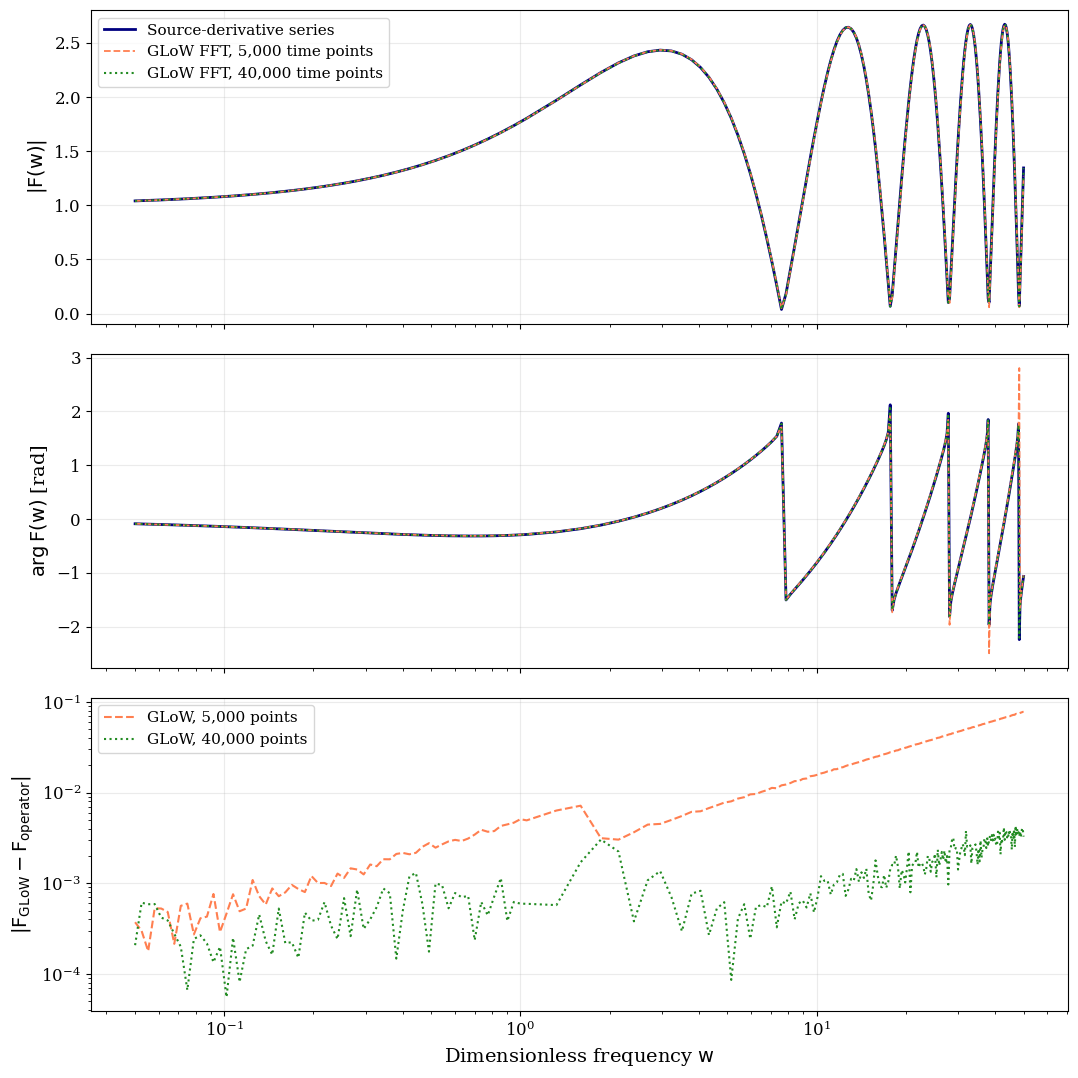

Largest shear order used: 23
Largest final relative term: 1.77e-15


In [7]:
# The original 5,000-point GLoW time grid is retained for comparison.
# A finer grid helps reveal its numerical convergence for this shear case.
W_CR = np.r_[np.geomspace(0.05, 1, 60), np.linspace(1.05, 50, 180)]
F_OPERATOR = operator_pm_shear(W_CR)
coarse_response, coarse_method = glow_numerical(
    models['PM + external shear'], SOURCE_Y, w_min=0.05, w_max=50)
fine_response, fine_method = glow_numerical(
    models['PM + external shear'], SOURCE_Y, w_min=0.05, w_max=50,
    nt=40000, n_above_discard=9)
F_COARSE = coarse_method(W_CR)
F_FINE = fine_method(W_CR)

fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
axes[0].plot(W_CR, abs(F_OPERATOR), color='navy', label='Source-derivative series')
axes[0].plot(W_CR, abs(F_COARSE), color='coral', ls='--', lw=1.3,
             label='GLoW FFT, 5,000 time points')
axes[0].plot(W_CR, abs(F_FINE), color='forestgreen', ls=':', lw=1.5,
             label='GLoW FFT, 40,000 time points')
axes[0].set_ylabel(r'$|F(w)|$')
axes[0].legend(fontsize=11)

axes[1].plot(W_CR, np.angle(F_OPERATOR), color='navy')
axes[1].plot(W_CR, np.angle(F_COARSE), color='coral', ls='--', lw=1.3)
axes[1].plot(W_CR, np.angle(F_FINE), color='forestgreen', ls=':', lw=1.5)
axes[1].set_ylabel(r'$\arg F(w)$ [rad]')

# Absolute complex errors remain meaningful near a destructive-interference minimum.
for values, label, color, style in [
    (F_COARSE, 'GLoW, 5,000 points', 'coral', '--'),
    (F_FINE, 'GLoW, 40,000 points', 'forestgreen', ':')]:
    difference = abs(values - F_OPERATOR)
    axes[2].plot(W_CR, difference, color=color, ls=style, lw=1.5, label=label)
    print(f'{label}: median |complex difference| = {np.median(difference):.3e}; '
          f'maximum = {np.max(difference):.3e}')
axes[2].set(ylabel=r'$|F_{\rm GLoW}-F_{\rm operator}|$',
            xlabel=r'Dimensionless frequency $w$', yscale='log')
axes[2].legend(fontsize=11)
for ax in axes:
    ax.set_xscale('log')
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
print('Largest shear order used:', np.max(operator_pm_shear.last_orders))
print('Largest final relative term:', f'{np.max(operator_pm_shear.last_relative_terms):.2e}')

The analytic series and the independent contour integral agree at the three checked frequencies
within numerical precision. The last retained shear term is below the specified tolerance
throughout the plotted grid. This supports the analytic result for the aligned PM plus shear
configuration.

The GLoW curves visually overlap the analytic one, but their complex differences depend on
time-grid resolution. In this execution, increasing GLoW’s time grid from 5,000 to 40,000
points reduced the median absolute complex difference from about $2.7\times10^{-2}$ to
$1.3\times10^{-3}$. GLoW printed contour-bracketing warnings for this lens. The refined
curve is therefore a numerical comparison, not an exact reference; the independent contour
integral provides a separate check of the analytic series at $w=1,5,10$. Relative errors are
avoided here because $F$ approaches zero at some interference minima.

## Direct numerical checks against the GLoW paper

GLoW's [Figs. 8–9](https://arxiv.org/pdf/2409.04606) use $y=0.3$ and $y=1.2$ for
SIS and PM, plotting the numerical $F$ and its relative difference from the formula.
The following panels repeat those parameters and show the complex relative difference
$|F_{\rm numerical}/F_{\rm formula}-1|$. The formula is evaluated independently above.


PM, y=0.3: median 4.27e-06, maximum 2.78e-04


PM, y=1.2: median 2.86e-06, maximum 2.86e-05
SIS, y=0.3: median 8.04e-06, maximum 1.89e-04
SIS, y=1.2: median 6.25e-05, maximum 1.19e-03


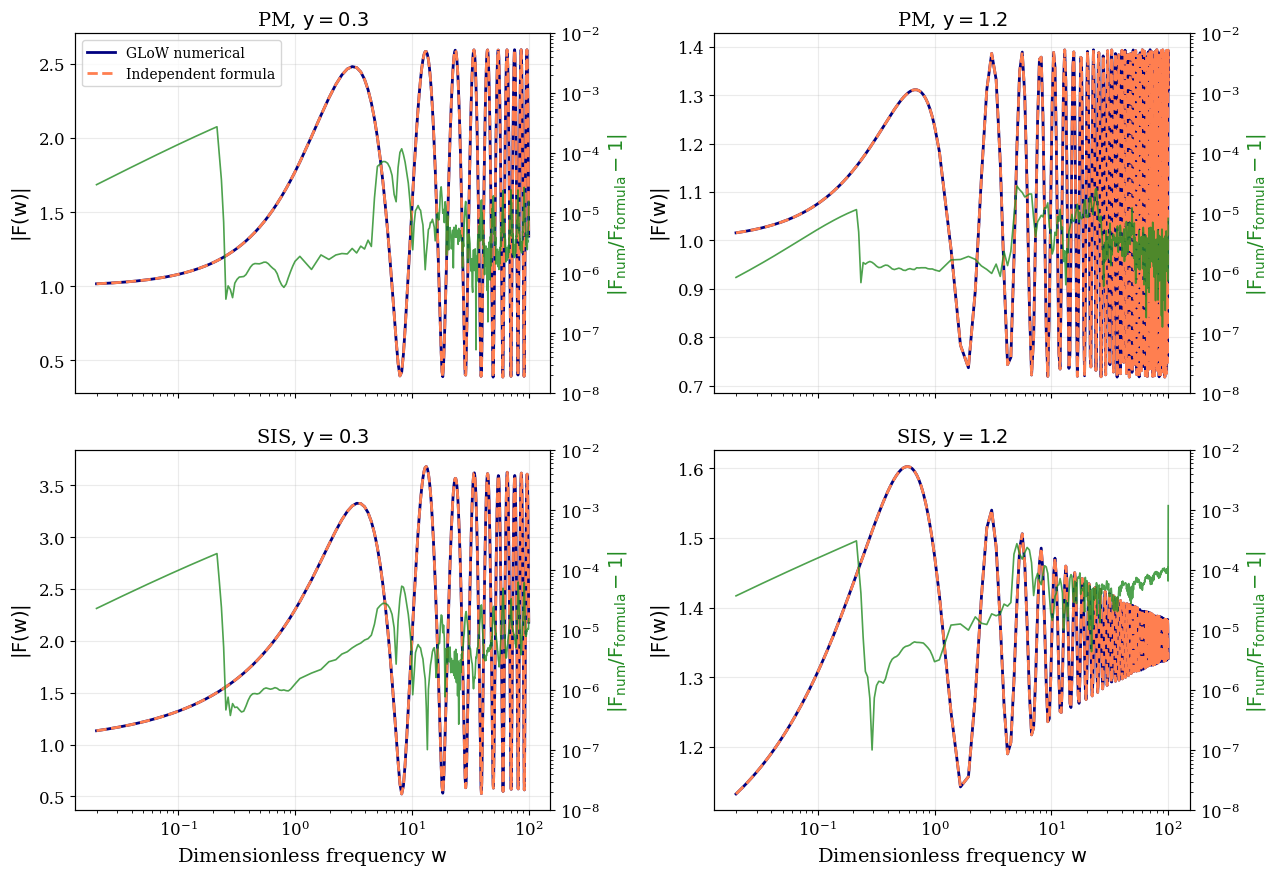

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
for row, (label, lens_class, formula) in enumerate([
    ('PM', lenses.Psi_PointLens, point_mass_formula),
    ('SIS', lenses.Psi_SIS, sis_formula),
]):
    for col, y in enumerate((0.3, 1.2)):
        response, method = glow_numerical(lens_class({'psi0': 1}), y)
        w_check = np.r_[np.geomspace(0.02, 1, 90), np.linspace(1.1, 100, 350)]
        numerical = method(w_check)
        exact = formula(w_check, y)
        relative = abs(numerical/exact - 1)
        ax = axes[row, col]
        ax.plot(w_check, abs(numerical), color='navy', label='GLoW numerical')
        ax.plot(w_check, abs(exact), color='coral', ls='--', label='Independent formula')
        ax.set(xscale='log', ylabel=r'$|F(w)|$', title=fr'{label}, $y={y}$')
        ax.grid(alpha=0.25)
        error_ax = ax.twinx()
        error_ax.plot(w_check, relative, color='forestgreen', lw=1.2, alpha=0.8,
                      label='Relative complex difference')
        error_ax.set_yscale('log')
        error_ax.set_ylim(1e-8, 1e-2)
        error_ax.set_ylabel(r'$|F_{\rm num}/F_{\rm formula}-1|$', color='forestgreen')
        print(f'{label}, y={y}: median {np.median(relative):.2e}, maximum {np.max(relative):.2e}')
axes[0, 0].legend(loc='best', fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel(r'Dimensionless frequency $w$')
fig.tight_layout()
plt.show()

## Takahashi and Nakamura (2003), Figs. 2–3

The published curves use $y=0.1,0.3,1,3$ for each lens, over $10^{-3}\leq w\leq100$.
The smooth PM curves use GLoW and their points use the independent PM formula.
The smooth SIS curves use the independent SIS formula and their points use GLoW's Python routine.
The points and curves agree over the plotted range.
The strongest oscillations occur near alignment; for SIS at $y=3$, only one ordinary
geometric image exists, yet the wave-optics curve still has a decaying modulation.


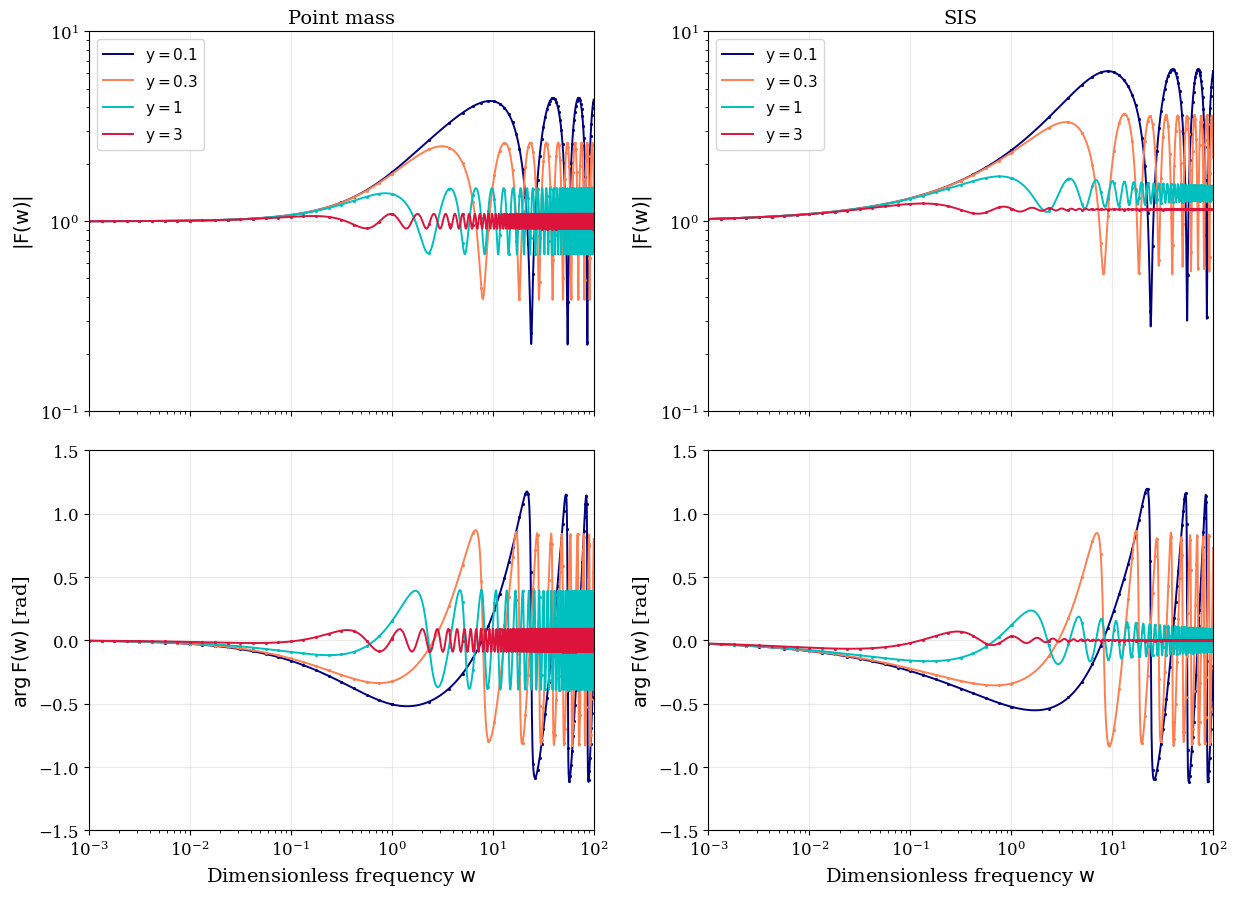

In [9]:
W_PAPER = np.r_[np.geomspace(1e-3, 1, 250), np.linspace(1.01, 100, 1400)]
W_SAMPLES = np.r_[np.geomspace(1e-3, 1, 25), np.linspace(1.01, 100, 75)]
source_positions = (0.1, 0.3, 1.0, 3.0)
fig, axes = plt.subplots(2, 2, figsize=(12.6, 9.2), sharex=True)
for col, label in enumerate(('Point mass', 'SIS')):
    for y, color in zip(source_positions, my_colors):
        if label == 'Point mass':
            # Smooth curve: installed GLoW. Sparse points: the independent Eq. 17.
            amplification = freq_domain_c.Fw_AnalyticPointLens_C(
                y, {'parallel': False})(W_PAPER)
            sample = point_mass_formula(W_SAMPLES, y)
        else:
            # Smooth curve: independent SIS Eq. 65. Sparse points: installed GLoW.
            # The angular integral needs more points when both y and w are large.
            n_angle = 768 if y == 3.0 else 256
            amplification = sis_formula(W_PAPER, y, n_angle=n_angle)
            sample = freq_domain.Fw_SemiAnalyticSIS(y)(W_SAMPLES)
        axes[0, col].plot(W_PAPER, abs(amplification), color=color, lw=1.4,
                          label=fr'$y={y:g}$')
        axes[0, col].plot(W_SAMPLES, abs(sample), color=color, ls='none', marker='.', ms=2.5)
        axes[1, col].plot(W_PAPER, np.angle(amplification), color=color, lw=1.4)
        axes[1, col].plot(W_SAMPLES, np.angle(sample), color=color, ls='none', marker='.', ms=2.5)
    axes[0, col].set(title=label, xscale='log', yscale='log',
                     xlim=(1e-3, 100), ylim=(0.1, 10), ylabel=r'$|F(w)|$')
    axes[1, col].set(xscale='log', xlim=(1e-3, 100), ylim=(-1.5, 1.5),
                     ylabel=r'$\arg F(w)$ [rad]', xlabel=r'Dimensionless frequency $w$')
    for ax in axes[:, col]:
        ax.grid(alpha=0.25)
    axes[0, col].legend(fontsize=11)
fig.tight_layout()
plt.show()

**Published reference:** [source paper](https://arxiv.org/pdf/astro-ph/0305055). The image is a crop of the cited figure.

![Takahashi and Nakamura 2003, Figs. 2 and 3](attachment:Takahashi and Nakamura 2003, Figs. 2 and 3.jpg)
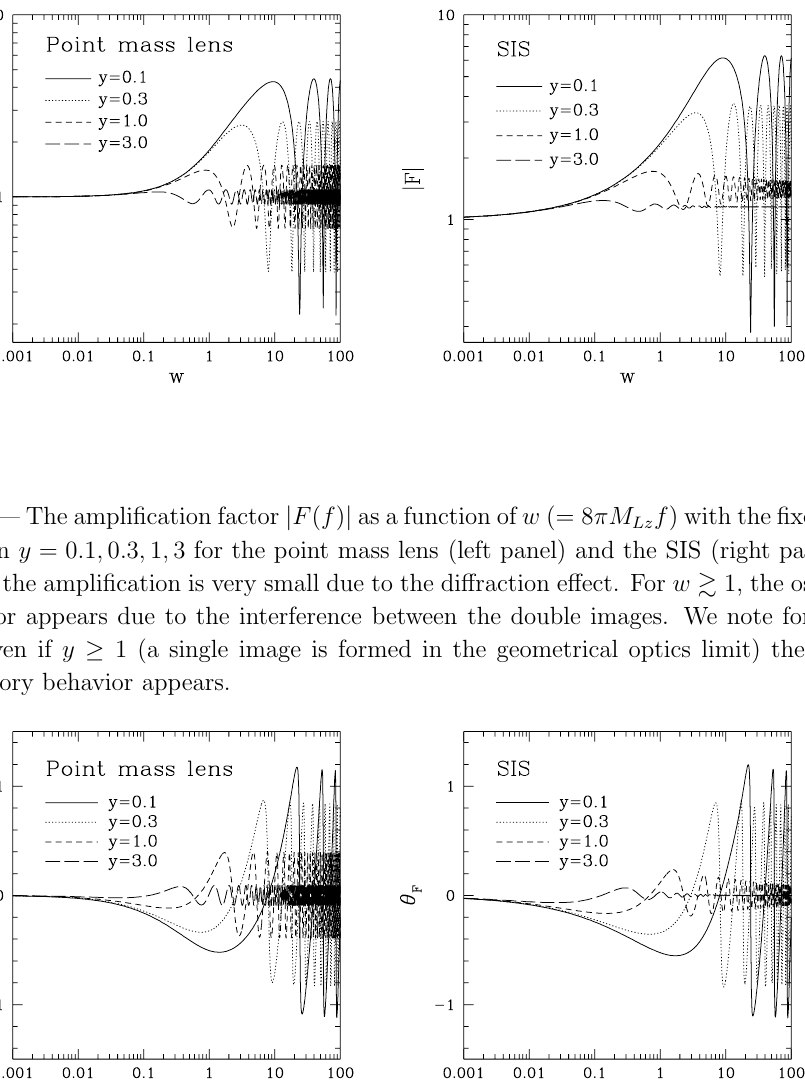

## FIONA paper, Fig. 10: isolated SIS

[Ephremidze et al., Fig. 10](https://arxiv.org/pdf/2603.12333) overlays FIONA and GLoW
for an SIS with $\psi_0=1$, $y=0.25$, and $0<w<100$. The published peak spacing and
range can be compared directly with the newly installed GLoW results below. The cited
figure is included beneath the new plot for a visual check. This is a comparison with
published curves; it is not an execution of FIONA.


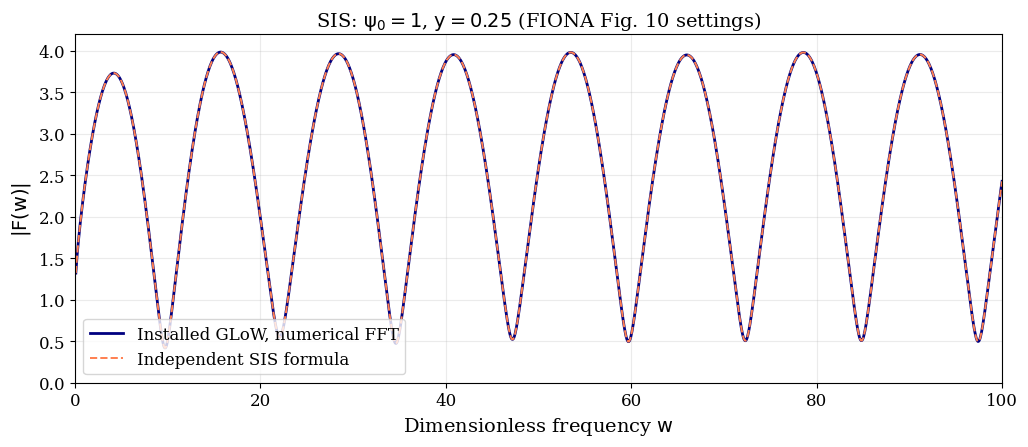

Maximum relative complex difference from SIS formula: 3.45e-04


In [10]:
w_fiona = np.linspace(0.1, 100, 1500)
y_fiona = 0.25
response_fiona, numerical_fiona = glow_numerical(
    lenses.Psi_SIS({'psi0': 1}), y_fiona, w_min=0.05, w_max=100)
formula_fiona = sis_formula(w_fiona, y_fiona)
f_numerical = numerical_fiona(w_fiona)
fig, ax = plt.subplots(figsize=(10.5, 4.7))
ax.plot(w_fiona, abs(f_numerical), color='navy', label='Installed GLoW, numerical FFT')
ax.plot(w_fiona, abs(formula_fiona), color='coral', ls='--', lw=1.4,
        label='Independent SIS formula')
ax.set(xlabel=r'Dimensionless frequency $w$', ylabel=r'$|F(w)|$',
       title=r'SIS: $\psi_0=1$, $y=0.25$ (FIONA Fig. 10 settings)',
       xlim=(0, 100), ylim=(0, 4.2))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
print('Maximum relative complex difference from SIS formula:',
      f'{np.max(abs(f_numerical/formula_fiona - 1)):.2e}')

**Published reference:** [source paper](https://arxiv.org/pdf/2603.12333). The image is a crop of the cited figure.

![FIONA 2026, Fig. 10](attachment:FIONA 2026, Fig. 10.jpg)
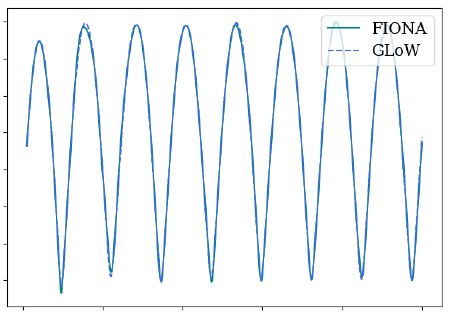

## Interpretation and limits

The direct formula checks test the installed PM and SIS implementations, including their complex
phase. The five-model plot shows how a small shear changes the interference pattern and how the
NFW curve differs from the compact and isothermal lenses. The geometric-optics curves are
high-frequency limits, not alternative wave-optics solvers.

The FIONA comparison uses a published SIS figure with identical lens settings. No numerical
FIONA table is available in that paper, so no quantitative FIONA–GLoW residual is claimed.
FIONA's other plots include elliptical or multicomponent lenses with different parameters;
they cannot be overlaid on the isolated NFW or the two simple shear cases here.

For a gravitational-wave waveform using the common $e^{-2\pi i f t}$ Fourier convention,
check the conjugation convention before multiplying it by GLoW's $F$; see
[GLoW's Fourier-convention note](https://github.com/glow-astro/GLoW/blob/master/FOURIER_CONVENTION.md).


## Computational cost

The timings use the five lens configurations at $y=0.3$ and 256 frequencies logarithmically
spaced over $0.05\leq w\leq50$. Each calculation runs with one thread. A **new calculation**
includes preparation for a given lens and source followed by the 256-frequency evaluation.
A **repeat evaluation** uses the same prepared object for another frequency grid. Lens-object
creation and plotting are outside both timings. Each time is the median of repeated runs after
one warm-up run. Time per frequency is the average over the grid, not the cost of a separate
single-frequency call.

For GLoW's general method, preparation means computing the time-domain response and regularized
FFT. The PM plus shear case has both the original 5,000-point time grid and a more accurate
40,000-point grid. For the source-derivative method, preparation means building the radial
weights; its frequency evaluations use 50-digit `mpmath` hypergeometric functions. The isolated
PM and SIS cases include GLoW's dedicated routines and the independent formulas above. The PM
reference uses 40-digit `mpmath`, while the SIS reference uses 256-point angular quadrature.

The general FFT can reuse its preparation for many frequency grids at fixed lens and source.
Changing either requires new preparation. These are wall-clock times on the current machine;
absolute milliseconds will change on another computer. See [GLoW, Sec. VI](https://arxiv.org/pdf/2409.04606)
for its algorithms and published benchmarks.

In [11]:
from statistics import median
from time import perf_counter
import platform
import pandas as pd

W_COST = np.geomspace(0.05, 50, 256)
N_SETUP_REPEATS = 3
N_EVAL_REPEATS = 5


def median_call_seconds(call, repeats):
    """Return the median wall-clock time; warm-up is excluded from the result."""
    call()
    elapsed = []
    for _ in range(repeats):
        start = perf_counter()
        call()
        elapsed.append(perf_counter() - start)
    return median(elapsed)


def benchmark_method(name, make_method, evaluate, setup_repeats=N_SETUP_REPEATS):
    """Time preparation and a 256-frequency evaluation separately."""
    setup_seconds = median_call_seconds(make_method, setup_repeats)
    method = make_method()
    evaluation_seconds = median_call_seconds(
        lambda: evaluate(method, W_COST), N_EVAL_REPEATS
    )
    return {'Method': name, 'Setup (ms)': 1e3*setup_seconds,
            'Grid evaluation (ms)': 1e3*evaluation_seconds,
            'New calculation (ms)': 1e3*(setup_seconds + evaluation_seconds),
            'Time per frequency (us)': 1e6*evaluation_seconds/len(W_COST)}


cost_rows = []
for name, lens in models.items():
    cost_rows.append(benchmark_method(
        name + ' — general FFT',
        lambda lens=lens: glow_numerical(lens, SOURCE_Y, w_min=0.05, w_max=50)[1],
        lambda method, w: method(w)
    ))

cost_rows.append(benchmark_method(
    'PM + external shear — refined FFT',
    lambda: glow_numerical(models['PM + external shear'], SOURCE_Y,
                           w_min=0.05, w_max=50, nt=40000, n_above_discard=9)[1],
    lambda method, w: method(w)
))
cost_rows.append(benchmark_method(
    'PM + external shear — operator series',
    lambda: ChangRefsdalOperator(SOURCE_Y, SHEAR),
    lambda method, w: method(w)
))

cost_rows.append(benchmark_method(
    'PM — GLoW formula (C)',
    lambda: freq_domain_c.Fw_AnalyticPointLens_C(SOURCE_Y, {'parallel': False}),
    lambda method, w: method(w)
))
cost_rows.append(benchmark_method(
    'SIS — GLoW formula (C)',
    lambda: freq_domain_c.Fw_SemiAnalyticSIS_C(SOURCE_Y, {'parallel': False}),
    lambda method, w: method(w)
))
# These independent reference functions have no separate object to prepare.
for name, reference in [('PM — independent formula', point_mass_formula),
                        ('SIS — independent formula', sis_formula)]:
    evaluation_seconds = median_call_seconds(
        lambda reference=reference: reference(W_COST, SOURCE_Y), N_EVAL_REPEATS
    )
    cost_rows.append({'Method': name, 'Setup (ms)': 0.0,
                      'Grid evaluation (ms)': 1e3*evaluation_seconds,
                      'New calculation (ms)': 1e3*evaluation_seconds,
                      'Time per frequency (us)': 1e6*evaluation_seconds/len(W_COST)})

costs = pd.DataFrame(cost_rows).set_index('Method')
print(f'{platform.processor() or platform.machine()} | Python {platform.python_version()} '
      f'| GLoW {version("glow")} | one thread | {len(W_COST)} frequencies')
display(costs.round(3))

GSL ERROR: endpoints do not straddle y=0 [brent.c:74]


GSL ERROR: endpoints do not straddle y=0 [brent.c:74]


GSL ERROR: endpoints do not straddle y=0 [brent.c:74]


GSL ERROR: endpoints do not straddle y=0 [brent.c:74]


GSL ERROR: endpoints do not straddle y=0 [brent.c:74]


x86_64 | Python 3.10.20 | GLoW 0.1 | one thread | 256 frequencies


,Setup (ms),Grid evaluation (ms),New calculation (ms),Time per frequency (us)
Method,,,,
Isolated PM — general FFT,8.509,0.132,8.641,0.516
PM + external shear — general FFT,262.230,0.126,262.356,0.492
Isolated SIS — general FFT,5.091,0.247,5.338,0.965
SIS + external shear — general FFT,182.567,0.150,182.717,0.587
NFW — general FFT,10.054,0.095,10.149,0.372
PM + external shear — refined FFT,2074.937,0.203,2075.140,0.794
PM + external shear — operator series,53.462,1762.139,1815.601,6883.357
PM — GLoW formula (C),0.047,0.032,0.079,0.126
SIS — GLoW formula (C),0.029,0.706,0.734,2.757


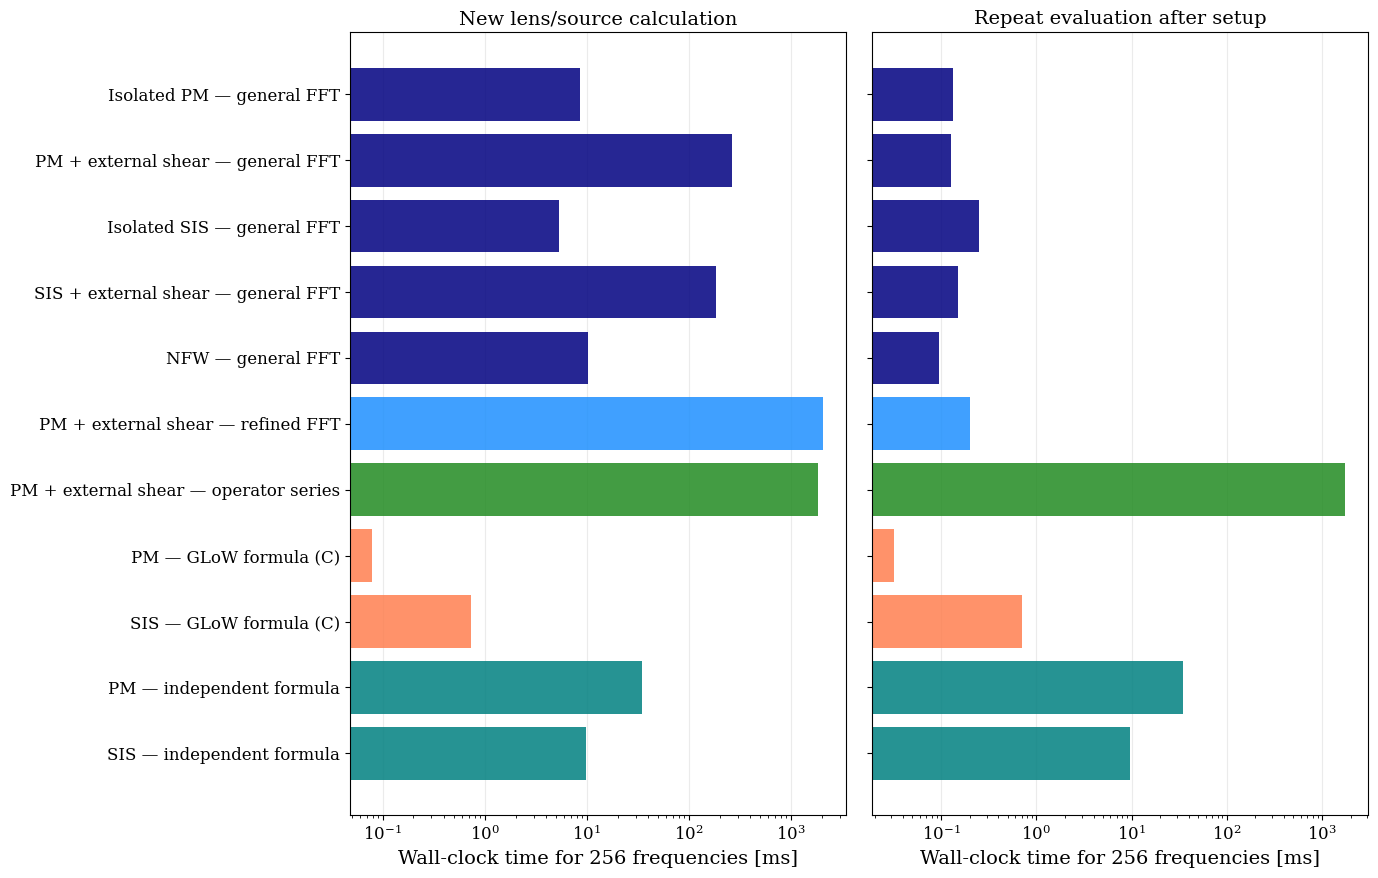

Isolated PM: general FFT / dedicated formula cost ratio = 109.1 for a new calculation, 4.1 for a repeat grid.
Isolated SIS: general FFT / dedicated formula cost ratio = 7.3 for a new calculation, 0.4 for a repeat grid.
PM + external shear — general FFT: FFT / source-derivative series cost ratio = 0.14 for a new calculation, 7.15e-05 for a repeat grid.
PM + external shear — refined FFT: FFT / source-derivative series cost ratio = 1.14 for a new calculation, 1.15e-04 for a repeat grid.


In [12]:
# Compare complete new calculations with the cost of another grid after setup.
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharey=True)
plot_rows = costs
positions = np.arange(len(plot_rows))
colors = ['navy']*5 + ['dodgerblue', 'forestgreen'] + ['coral']*2 + ['teal']*2
for ax, column, title in zip(
    axes,
    ('New calculation (ms)', 'Grid evaluation (ms)'),
    ('New lens/source calculation', 'Repeat evaluation after setup')
):
    ax.barh(positions, plot_rows[column], color=colors, alpha=0.85)
    ax.set_xscale('log')
    ax.set_xlabel('Wall-clock time for 256 frequencies [ms]')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.25)
    ax.set_axisbelow(True)
axes[0].set_yticks(positions, plot_rows.index)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

for lens_name, formula_name in [('Isolated PM', 'PM — GLoW formula (C)'),
                                ('Isolated SIS', 'SIS — GLoW formula (C)')]:
    numerical = costs.loc[lens_name + ' — general FFT']
    formula = costs.loc[formula_name]
    new_ratio = numerical['New calculation (ms)']/formula['New calculation (ms)']
    repeat_ratio = numerical['Grid evaluation (ms)']/formula['Grid evaluation (ms)']
    print(f'{lens_name}: general FFT / dedicated formula cost ratio = '
          f'{new_ratio:.1f} for a new calculation, {repeat_ratio:.1f} for a repeat grid.')

operator_cost = costs.loc['PM + external shear — operator series']
for method_name in ('PM + external shear — general FFT',
                    'PM + external shear — refined FFT'):
    fft_cost = costs.loc[method_name]
    print(f'{method_name}: FFT / source-derivative series cost ratio = '
          f'{fft_cost["New calculation (ms)"]/operator_cost["New calculation (ms)"]:.2f} '
          f'for a new calculation, '
          f'{fft_cost["Grid evaluation (ms)"]/operator_cost["Grid evaluation (ms)"]:.2e} '
          f'for a repeat grid.')


The independent PM formula is relatively expensive because each frequency evaluates a complex
hypergeometric function at arbitrary precision. The fast GLoW PM routine uses approximations
tested against that expression. The SIS formula removes the two-dimensional diffraction integral
but still requires angular integration.

The PM plus shear source-derivative series is analytic, but its hypergeometric evaluations are
expensive in this direct Python implementation. The refined GLoW FFT costs more than its coarse
version and reduces the complex difference from the independently checked series. The SIS plus
shear and NFW cases have no comparable formula in the references used here. Timing ratios near
one should be treated cautiously because wall-clock measurements fluctuate.